In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
print("Probability analysis started")

Probability analysis started


In [2]:
# Example contingency table: customer purchases
table = pd.DataFrame(
    {
        "Purchased": [30, 20],
        "Not Purchased": [10, 40]
    },
    index=["Saw Advertisement", "No Advertisement"]
)

print(table)

total = table.to_numpy().sum()

# P(A): customer saw the advertisement
p_a = table.loc["Saw Advertisement"].sum() / total

# P(B): customer purchased
p_b = table["Purchased"].sum() / total

# P(A intersection B): saw advertisement and purchased
p_a_and_b = table.loc["Saw Advertisement", "Purchased"] / total

# P(B | A): purchased given that they saw the advertisement
p_b_given_a = (
    table.loc["Saw Advertisement", "Purchased"]
    / table.loc["Saw Advertisement"].sum()
)

print(f"P(A) = {p_a:.2f}")
print(f"P(B) = {p_b:.2f}")
print(f"P(A and B) = {p_a_and_b:.2f}")
print(f"P(B | A) = {p_b_given_a:.2f}")

                   Purchased  Not Purchased
Saw Advertisement         30             10
No Advertisement          20             40
P(A) = 0.40
P(B) = 0.50
P(A and B) = 0.30
P(B | A) = 0.75


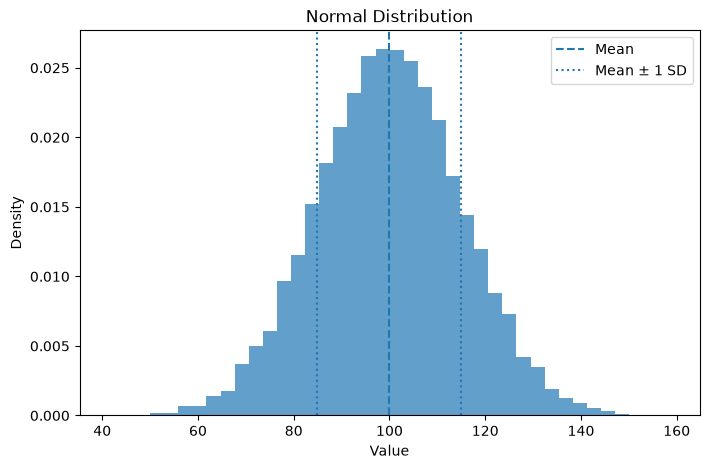

Within 1 standard deviation(s): 68.38%
Within 2 standard deviation(s): 95.38%
Within 3 standard deviation(s): 99.73%


In [3]:
data = np.random.normal(loc=100, scale=15, size=10000)

mean = np.mean(data)
std = np.std(data)

plt.figure(figsize=(8, 5))
plt.hist(data, bins=40, density=True, alpha=0.7)
plt.axvline(mean, linestyle="--", label="Mean")
plt.axvline(mean - std, linestyle=":", label="Mean ± 1 SD")
plt.axvline(mean + std, linestyle=":")
plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.show()

for k in [1, 2, 3]:
    percentage = np.mean(np.abs(data - mean) <= k * std) * 100
    print(f"Within {k} standard deviation(s): {percentage:.2f}%")

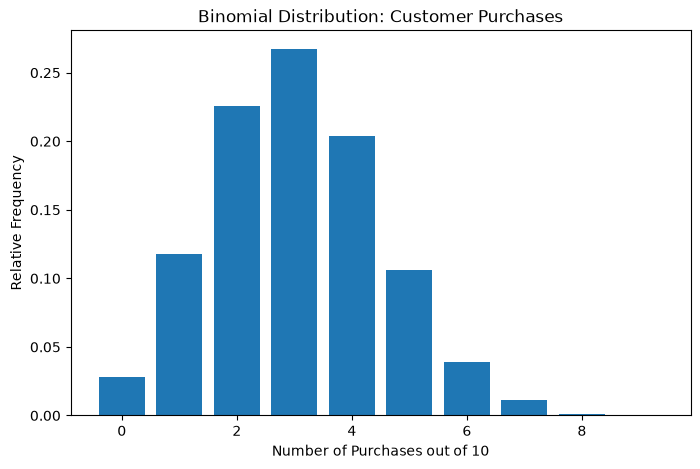

Simulated average purchases: 3.0375
Theoretical average purchases: 3.0


In [4]:
# Example: 10 customers, each has a 30% purchase probability
trials = 10
purchase_probability = 0.30

results = np.random.binomial(
    n=trials,
    p=purchase_probability,
    size=10000
)

plt.figure(figsize=(8, 5))
values, counts = np.unique(results, return_counts=True)
plt.bar(values, counts / len(results))
plt.title("Binomial Distribution: Customer Purchases")
plt.xlabel("Number of Purchases out of 10")
plt.ylabel("Relative Frequency")
plt.show()

print("Simulated average purchases:", results.mean())
print("Theoretical average purchases:", trials * purchase_probability)


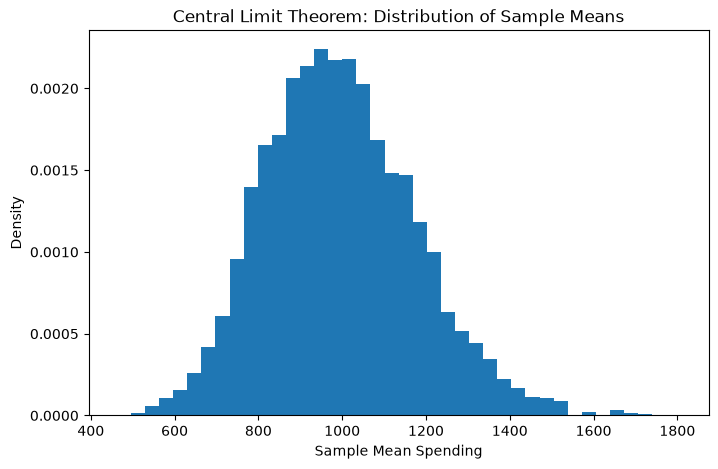

Population mean: 994.444831674456
Mean of sample means: 994.7393222152583
Theoretical standard error: 180.75521664388975
Observed standard deviation of sample means: 180.3008764428192


In [5]:
# A skewed population representing customer spending
population = np.random.exponential(scale=1000, size=100000)

sample_size = 30
number_of_samples = 5000

sample_means = np.array([
    np.mean(np.random.choice(population, size=sample_size))
    for _ in range(number_of_samples)
])

plt.figure(figsize=(8, 5))
plt.hist(sample_means, bins=40, density=True)
plt.title("Central Limit Theorem: Distribution of Sample Means")
plt.xlabel("Sample Mean Spending")
plt.ylabel("Density")
plt.show()

print("Population mean:", population.mean())
print("Mean of sample means:", sample_means.mean())
print("Theoretical standard error:", population.std() / np.sqrt(sample_size))
print("Observed standard deviation of sample means:", sample_means.std())